In [1]:
import time
import os
import glob
import sys
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "font.family": "serif",
    "figure.dpi": 300,
})
import numpy as np
import meshio
from itertools import combinations
import torch
import torch.nn as nn
import pandas as pd
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
from network import CNetwork, GNetwork, GNNetwork,FGatedGNN, initialize_weights
from data_sampling import tanh_pattern_sampling, sine_wave_pattern_sampling, random_fixed_sampling, cross_pattern_sampling 
from plot_saver import setup_output_dirs, get_next_run_number

In [2]:
def add_noise(u, v, noise_level=0.05, seed=42):
    """
    Adds Gaussian noise with a given percentage level.
    noise_level: 0.05 for 5%, 0.1 for 10%, etc.
    """
    np.random.seed(seed)

    u_std = np.std(u)
    v_std = np.std(v)

    u_noisy = u + noise_level * u_std * np.random.randn(*u.shape)
    v_noisy = v + noise_level * v_std * np.random.randn(*v.shape)

    return u_noisy, v_noisy

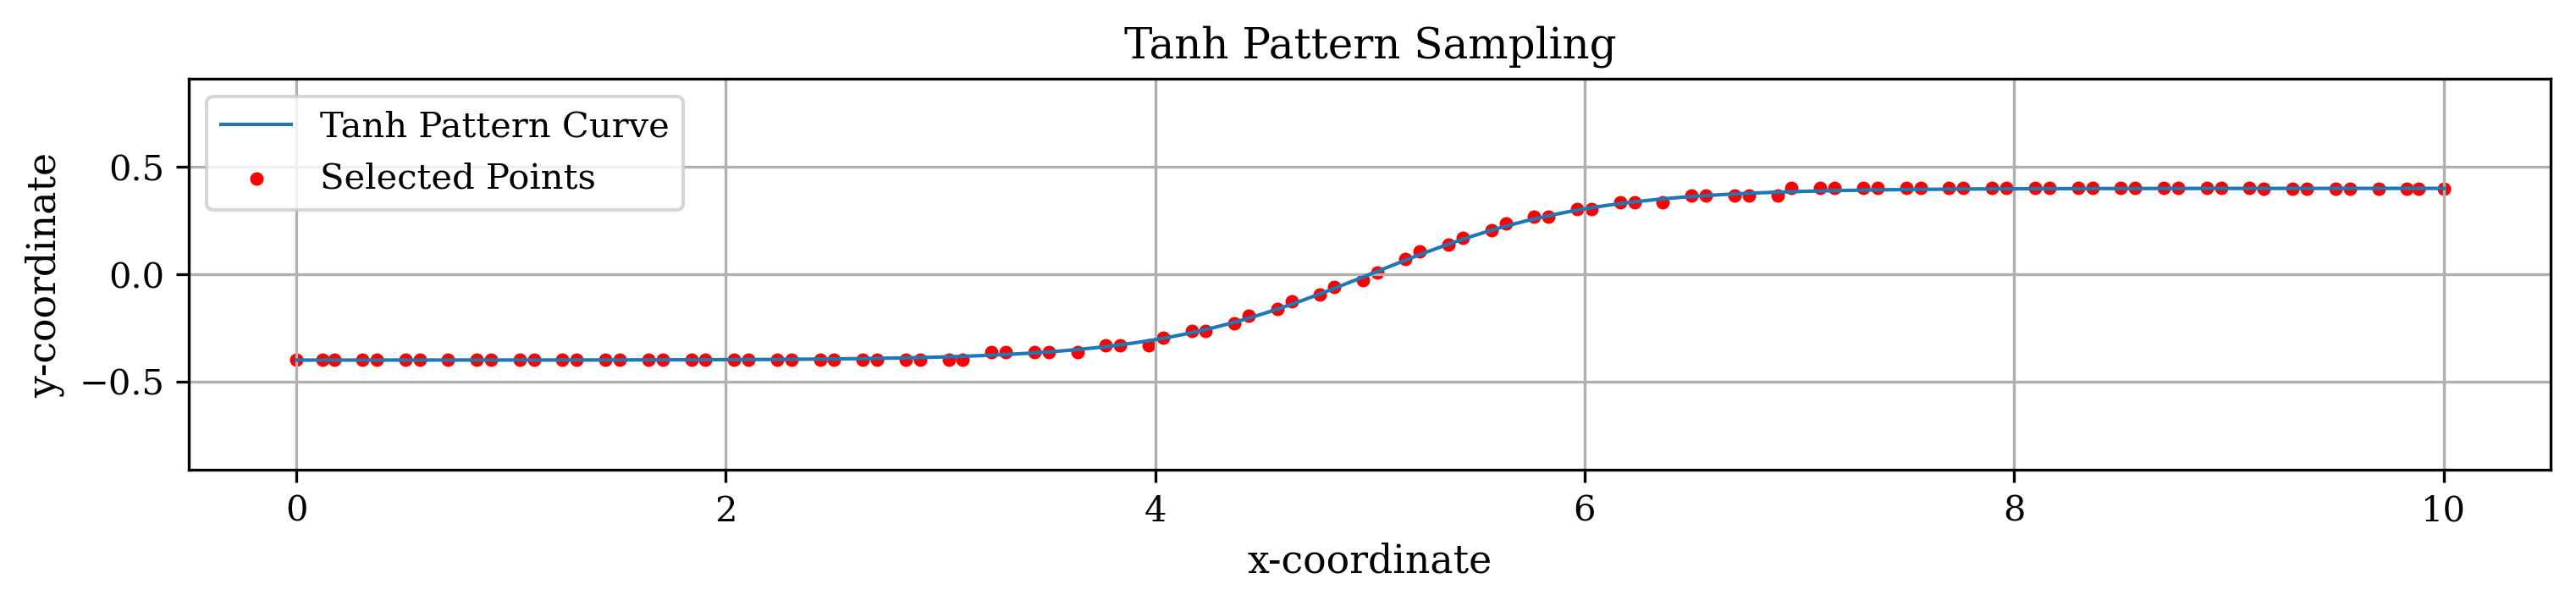

In [3]:
script_name = "GPINN-illpose-100data-without-noise-tanhpattern"
DIRS = setup_output_dirs(script_name)
torch.set_default_dtype(torch.float64) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
df = pd.read_csv("Input/data")
df.columns = df.columns.str.strip()

x_cfd = df["x-coordinate"].to_numpy()
y_cfd = df["y-coordinate"].to_numpy()
u_cfd = df["x-velocity"].to_numpy()
v_cfd = df["y-velocity"].to_numpy()

X_CFD = torch.from_numpy(
    np.column_stack((x_cfd, y_cfd))
).double()

indices, xy_sampled, u_sampled, v_sampled, (x_p, y_p), (xc, yc) = tanh_pattern_sampling(
    x_data=x_cfd,
    y_data=y_cfd,
    xy=X_CFD,
    u=u_cfd,
    v=v_cfd,
    n_samples=100,
    save_path=os.path.join(DIRS["plots"], "selected_points.png")
)

# noise_level = 0.2

# u_sampled, v_sampled = add_noise(
#     u_sampled, 
#     v_sampled, 
#     noise_level=noise_level
# )

In [6]:
class Pinns:
    def __init__(self):
        # Device
        self.device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
        print("CUDA Available:", torch.cuda.is_available())

        # Physical parameters
        self.rho = 1.0        # Density [kg/m³]
        self.eta_0 = 0.01     # Zero-shear viscosity [Pa·s]
        self.eta_inf = 0.005  # Infinite-shear viscosity [Pa·s]
        self.lam = 1.0         # Relaxation time [s]
        self.n_cy = 0.5       # Power-law index
        self.a_cy = 2.0      # Yasuda parameter

        # Geometry
        mesh = meshio.read(r"Input/mesh.msh")
        coords_np = mesh.points[:, :2]
        cells  = mesh.cells
        n_nodes   = coords_np.shape[0]
        # edge groups
        interior_edges = cells[0].data
        outlet_edges   = cells[1].data
        wall1_edges    = cells[2].data
        wall2_edges    = cells[3].data
        wall3_edges    = cells[4].data
        inlet_edges    = cells[5].data
        
        # all boundary edges
        boundary_edges = np.vstack([
            outlet_edges,
            wall1_edges,
            wall2_edges,
            wall3_edges,
            inlet_edges
        ])
        
        # node classification
        boundary_nodes = np.unique(boundary_edges)
        all_nodes = np.arange(coords_np.shape[0])
        interior_nodes = np.setdiff1d(all_nodes, boundary_nodes)
        
        # convert to torch
        self.boundary_ids = torch.tensor(boundary_nodes, dtype=torch.long, device=self.device)
        self.interior_ids = torch.tensor(interior_nodes, dtype=torch.long, device=self.device)

        # build adjacency
        adj_np = np.zeros((n_nodes, n_nodes), dtype=np.float32)
        for cell_block in mesh.cells:
            for elem in cell_block.data:
                for i, j in combinations(elem, 2):
                    adj_np[i, j] = 1.0
                    adj_np[j, i] = 1.0
        np.fill_diagonal(adj_np, 1.0)

        _, self.nb_ids = self._build_ls_matrices(coords_np, adj_np)
                    
        # normalize once
        deg     = adj_np.sum(axis=1)
        d_inv   = np.where(deg > 0, 1.0 / np.sqrt(deg), 0.0)
        adj_norm = (adj_np * d_inv[:, None]) * d_inv[None, :]
        adj_norm = torch.tensor(adj_norm, dtype=torch.float32, device=self.device)
        #model
        self.network = FGatedGNN(num_input=2,fourier_features=10,layers=[64, 64, 64],num_output=3,scale=1.0).to(self.device).float()
        self.network.set_adj(adj_norm.float())
        
        # X holds ALL node coords
        self.X_all = torch.tensor(coords_np, dtype=torch.float32,
                                   requires_grad=True, device=self.device) 
        self.X_all = self.X_all.float()
        coords_mesh = coords_np
        coords_data = xy_sampled.cpu().numpy()
        
        from scipy.spatial import cKDTree
        tree = cKDTree(coords_mesh)
        _, idx = tree.query(coords_data)
        
        self.data_ids = torch.tensor(idx, dtype=torch.long, device=self.device)
        self.u_data = torch.tensor(u_sampled, dtype=torch.float32, device=self.device)
        self.v_data = torch.tensor(v_sampled, dtype=torch.float32, device=self.device)

        
        # Boundary condition values        
        u_bc = np.zeros(len(boundary_nodes), dtype=np.float32)
        v_bc = np.zeros(len(boundary_nodes), dtype=np.float32)
        
        coords_b  = coords_np[boundary_nodes]
        x_b = coords_b[:,0]
        y_b = coords_b[:,1]
        
        # inlet nodes
        inlet_nodes = np.unique(inlet_edges)
        inlet_mask = np.isin(boundary_nodes, inlet_nodes)
        
        # parabolic inlet profile
        u_bc[inlet_mask] = 24 * y_b[inlet_mask] * (0.5 - y_b[inlet_mask])
        v_bc[inlet_mask] = 0.0
        
        # wall nodes
        wall_nodes = np.unique(np.vstack([wall1_edges, wall2_edges, wall3_edges]))
        wall_mask = np.isin(boundary_nodes, wall_nodes)
        
        u_bc[wall_mask] = 0.0
        v_bc[wall_mask] = 0.0
        
        self.uv_bc = torch.tensor(
            np.stack([u_bc, v_bc], axis=1),
            dtype=torch.float32,
            device=self.device
        )
        
        # outlet nodes
        outlet_nodes = np.unique(outlet_edges)
        outlet_mask  = np.isin(boundary_nodes, outlet_nodes)
        self.outlet_ids = torch.tensor(
            boundary_nodes[outlet_mask],
            dtype=torch.long,
            device=self.device
        )
        self.p_outlet_bc = torch.zeros(
            outlet_mask.sum(),
            dtype=torch.float32,
            device=self.device
        )

        #Hard BC masks
        N = coords_np.shape[0]

        # wall mask
        wall_nodes  = np.unique(np.vstack([wall1_edges, wall2_edges, wall3_edges]))
        wall_vec    = np.zeros(N, dtype=np.float32)
        wall_vec[wall_nodes] = 1.0
        self.wall_mask = torch.tensor(wall_vec, dtype=torch.float32,
                                      device=self.device)

        #inverse
        # inlet mask + inlet u values
        # inlet_nodes_arr = np.unique(inlet_edges)
        # inlet_vec       = np.zeros(N, dtype=np.float32)
        # inlet_vec[inlet_nodes_arr] = 1.0
        # self.inlet_mask = torch.tensor(inlet_vec, dtype=torch.float32,
        #                                device=self.device)

        coords_all    = coords_np
        y_all         = coords_all[:, 1]
        # u_inlet_full  = np.zeros(N, dtype=np.float32)
        # u_inlet_full[inlet_nodes_arr] = (
        #     24.0 * y_all[inlet_nodes_arr] * (0.5 - y_all[inlet_nodes_arr])
        # )
        # self.u_inlet_hard = torch.tensor(u_inlet_full, dtype=torch.float32,
        #                                  device=self.device)

        # outlet mask (p = 0)
        outlet_nodes_arr = np.unique(outlet_edges)
        outlet_vec       = np.zeros(N, dtype=np.float32)
        outlet_vec[outlet_nodes_arr] = 1.0
        self.outlet_mask = torch.tensor(outlet_vec, dtype=torch.float32,
                                        device=self.device)

        self.free_mask_uv = (1.0 - self.wall_mask) #* (1.0 - self.inlet_mask)
        self.free_mask_p  = (1.0 - self.outlet_mask)

        # Loss and optimizers
        self.criterion = nn.MSELoss()
        self.adam = torch.optim.Adam(self.network.parameters(), lr=1e-4)
        self.optimizer = torch.optim.LBFGS(
            self.network.parameters(),
            lr=0.01,
            max_iter=2000,
            max_eval=2000,
            history_size=50,
            tolerance_grad=1e-8,
            tolerance_change=1.0 * np.finfo(float).eps,
            line_search_fn="strong_wolfe"
        )

        self.loss_history = []

    def _build_ls_matrices(self, coords_np, adj_np):
        n = coords_np.shape[0]
        nb_ids = []
        for i in range(n):
            neighbors = np.where(adj_np[i] > 0)[0]
            neighbors = neighbors[neighbors != i]
            nb_ids.append(neighbors.tolist())
    
        max_nb = max(len(nbs) for nbs in nb_ids)
    
        nb_idx_padded   = torch.full((n, max_nb), -1,    dtype=torch.long)
        nb_mask         = torch.zeros(n, max_nb,          dtype=torch.bool)
        ls_mats_padded  = torch.zeros(n, 2, max_nb,       dtype=torch.float32)
    
        for i in range(n):
            nbs = nb_ids[i]
            k   = len(nbs)
            if k < 2:
                continue
    
            nb_idx_padded[i, :k] = torch.tensor(nbs, dtype=torch.long)
            nb_mask[i, :k]       = True
    
            dx = coords_np[nbs] - coords_np[i]
            A  = dx
    
            try:
                ATA    = A.T @ A 
                ATAinv = np.linalg.inv(ATA + 1e-10 * np.eye(2))
                ls_mat = ATAinv @ A.T
                ls_mats_padded[i, :, :k] = torch.tensor(
                    ls_mat, dtype=torch.float32
                )
            except np.linalg.LinAlgError:
                pass
        self.nb_idx_padded  = nb_idx_padded.to(self.device)
        self.nb_mask        = nb_mask.to(self.device)
        self.ls_mats_padded = ls_mats_padded.to(self.device)
        self.max_nb         = max_nb
        self.n_nodes        = n
    
        return None, nb_ids


        
    # gradient function
    def gradient(self, scalar_field):
        if scalar_field.dim() == 2:
            scalar_field = scalar_field.squeeze(-1)
    
        safe_idx = self.nb_idx_padded.clamp(min=0)
        f_neighbors = scalar_field[safe_idx]
        f_center = scalar_field.unsqueeze(1)
    
        delta_f = (f_neighbors - f_center) * self.nb_mask.float()
    
        grad = torch.bmm(self.ls_mats_padded, delta_f.unsqueeze(-1))
        grad = grad.squeeze(-1)
    
        grad_x = grad[:, 0]
        grad_y = grad[:, 1]
    
        return grad_x, grad_y

        
    # Loss function
    def loss_f(self):
        uvp = self.network(self.X_all)
        u_raw = uvp[:, 0]
        v_raw = uvp[:, 1]
        p_raw = uvp[:, 2]

        # Data loss (sampled CFD points)
        u_pred = u_raw[self.data_ids]
        v_pred = v_raw[self.data_ids]
        
        loss_u_data = self.criterion(u_pred, self.u_data)
        loss_v_data = self.criterion(v_pred, self.v_data)
        
        loss_data_samples = loss_u_data + loss_v_data

        #Hard Boundary Conditions 
        u = self.free_mask_uv * u_raw #+ self.u_inlet_hard
        v = self.free_mask_uv * v_raw
        p = self.free_mask_p * p_raw

    
        du_dx, du_dy = self.gradient(u)
        dv_dx, dv_dy = self.gradient(v)
        dp_dx, dp_dy = self.gradient(p)
    
        gamma_dot_all = torch.sqrt(
            2.0*du_dx**2 + 2.0*dv_dy**2 +
            (du_dy + dv_dx)**2 + 1e-12
        )
        mu_all = (self.eta_inf +
                  (self.eta_0 - self.eta_inf) *
                  (1.0 + (self.lam * gamma_dot_all)**self.a_cy)
                  **((self.n_cy - 1.0) / self.a_cy))
    
        tau_xx_all = 2.0 * mu_all * du_dx
        tau_xy_all = mu_all * (du_dy + dv_dx)
        tau_yy_all = 2.0 * mu_all * dv_dy
    
        dtau_xx_dx, _          = self.gradient(tau_xx_all)
        dtau_xy_dx, dtau_xy_dy = self.gradient(tau_xy_all)
        _,          dtau_yy_dy = self.gradient(tau_yy_all)
    
        def interior(t): return t[self.interior_ids]
    
        u_i          = interior(u)
        v_i          = interior(v)
        du_dx_i      = interior(du_dx)
        du_dy_i      = interior(du_dy)
        dv_dx_i      = interior(dv_dx)
        dv_dy_i      = interior(dv_dy)
        dp_dx_i      = interior(dp_dx)
        dp_dy_i      = interior(dp_dy)
        dtau_xx_dx_i = interior(dtau_xx_dx)
        dtau_xy_dy_i = interior(dtau_xy_dy)
        dtau_xy_dx_i = interior(dtau_xy_dx)
        dtau_yy_dy_i = interior(dtau_yy_dy)
    
        continuity = du_dx_i + dv_dy_i
    
        momentum_x = (self.rho * (u_i*du_dx_i + v_i*du_dy_i)
                      + dp_dx_i
                      - (dtau_xx_dx_i + dtau_xy_dy_i))
    
        momentum_y = (self.rho * (u_i*dv_dx_i + v_i*dv_dy_i)
                      + dp_dy_i
                      - (dtau_xy_dx_i + dtau_yy_dy_i))
    
        loss_c  = self.criterion(continuity, torch.zeros_like(continuity))
        loss_mx = self.criterion(momentum_x, torch.zeros_like(momentum_x))
        loss_my = self.criterion(momentum_y, torch.zeros_like(momentum_y))
    
        loss_pde   = loss_c + loss_mx + loss_my
        loss_total = loss_pde + 10*loss_data_samples
        loss_data = loss_data_samples
    
        return loss_total, loss_data, loss_c, loss_mx, loss_my

    
    # Training loop
    def train(self, num_epochs=5000):
        self.network.train()
        run_number    = get_next_run_number(script_name)
        model_path    = os.path.join(DIRS["models"],  "model_best.pth")
        history_path  = os.path.join(DIRS["history"], f"loss_history_run{run_number:03d}.csv")
        time_path = os.path.join(DIRS["history"], f"adam_epoch_time_run{run_number:03d}.csv")
        print(f"Run {run_number:03d}")
        print(f"   Model   -> {model_path}  (overwrites previous)")
        print(f"   History -> {history_path}")
        epoch_times = []    
        checkpoint_path = "pinns_checkpoint.pth"
    
        for i in range(num_epochs):
            start_time = time.time()
            self.adam.zero_grad()
            loss_total, loss_data, loss_c, loss_mx, loss_my = self.loss_f()
            loss_total.backward()
            self.adam.step()
            self.loss_history.append({"epoch": i, "loss_total": loss_total.item()})
            epoch_duration = time.time() - start_time
            epoch_times.append({"epoch": i, "duration": epoch_duration})
            
            if i % 10 == 0:
                print(f"Epoch {i}: Total={loss_total.item():.3e}, "
                      f"BC={loss_data.item():.3e}, "
                      f"Cont={loss_c.item():.3e}, "
                      f"Mx={loss_mx.item():.3e}, My={loss_my.item():.3e}")
            if i % 100 == 0:
                torch.save(self.network.state_dict(), model_path)
                print(f"  Checkpoint saved -> {model_path}")
                
        df_time = pd.DataFrame(epoch_times)
        df_time.to_csv(time_path, index=False)
        print(f"Adam epoch times saved -> {time_path}")
                
        # LBFGS phase
        lbfgs_step = [0]
        adam_epochs  = num_epochs
        def closure():
            self.optimizer.zero_grad()
            loss_total, loss_data, loss_c, loss_mx, loss_my = self.loss_f()
            loss_total.backward()
            step = lbfgs_step[0]
            lbfgs_step[0] += 1
            
            self.loss_history.append({
                "epoch": adam_epochs + step,
                "loss_total": loss_total.item()
            })
            
            if step % 10 == 0:
                print(f"  [LBFGS {step:5d}] Loss={loss_total.item():.3e}")
            return loss_total
        print("Starting LBFGS...")
        self.optimizer.step(closure)
        
        torch.save(self.network.state_dict(), model_path)
        print(f"Final model saved -> {model_path}")
        
        df_run = pd.DataFrame(self.loss_history)
        df_run.to_csv(history_path, index=False)
        print(f"Run history saved -> {history_path}")

    def plot(self):
        self.network.eval()
        
        coords_np = self.X_all.detach().cpu().numpy()
        x_mesh    = coords_np[:, 0]
        y_mesh    = coords_np[:, 1]
        
        #1. Forward pass on mesh nodes
        with torch.no_grad():
            uvp_raw = self.network(self.X_all)
            u_raw   = uvp_raw[:, 0]
            v_raw   = uvp_raw[:, 1]
            p_raw   = uvp_raw[:, 2]

            u_t = self.free_mask_uv * u_raw #+ self.u_inlet_hard
            v_t = self.free_mask_uv * v_raw
            p_t = self.free_mask_p  * p_raw

            u_all = u_t.cpu().numpy()
            v_all = v_t.cpu().numpy()
            p_all = p_t.cpu().numpy()
    
        #2. Viscosity via autograd on mesh nodes
        with torch.no_grad():
            uvp_raw2 = self.network(self.X_all)
            u_t2 = self.free_mask_uv * uvp_raw2[:, 0] #+ self.u_inlet_hard
            v_t2 = self.free_mask_uv * uvp_raw2[:, 1]
        
            du_dx, du_dy = self.gradient(u_t2)
            dv_dx, dv_dy = self.gradient(v_t2)
        
            gamma_dot = torch.sqrt(
                2*du_dx**2 + 2*dv_dy**2 +
                (du_dy + dv_dx)**2 + 1e-12
            )
            eta_all = (self.eta_inf +
                       (self.eta_0 - self.eta_inf) *
                       (1 + (self.lam * gamma_dot)**self.a_cy)
                       **((self.n_cy - 1) / self.a_cy))
            eta_np = eta_all.cpu().numpy()
    
        #3. Build regular grid and interpolate PINN predictions
        nx_plot, ny_plot = 300, 100
        x_lin = np.linspace(x_mesh.min(), x_mesh.max(), nx_plot)
        y_lin = np.linspace(y_mesh.min(), y_mesh.max(), ny_plot)
        X_np, Y_np = np.meshgrid(x_lin, y_lin, indexing='ij')
    
        def to_grid(values):
            return griddata((x_mesh, y_mesh), values, (X_np, Y_np),
                            method='linear', fill_value=np.nan)
    
        u_grid   = to_grid(u_all)
        v_grid   = to_grid(v_all)
        p_grid   = to_grid(p_all)
        eta_grid = to_grid(eta_np)
    
        #4. Load CFD reference
        df = pd.read_csv("Input/data")
        df.columns = df.columns.str.strip()
    
        x_cfd        = df["x-coordinate"].values
        y_cfd        = df["y-coordinate"].values
        u_cfd        = df["x-velocity"].values
        v_cfd        = df["y-velocity"].values
        p_cfd        = df["pressure"].values
        viscosity_cfd = df["viscosity-lam"].values
    
        #5. PINN predictions at CFD points (via interpolation)
        u_pinn_cfd   = griddata((x_mesh, y_mesh), u_all,  (x_cfd, y_cfd), method='linear')
        v_pinn_cfd   = griddata((x_mesh, y_mesh), v_all,  (x_cfd, y_cfd), method='linear')
        p_pinn_cfd   = griddata((x_mesh, y_mesh), p_all,  (x_cfd, y_cfd), method='linear')
        eta_pinn_cfd = griddata((x_mesh, y_mesh), eta_np, (x_cfd, y_cfd), method='linear')
    
        #6. Errors
        eps     = 1e-12
        u_range = u_cfd.max()   - u_cfd.min()   + eps
        v_range = np.abs(v_cfd).max()            + eps
        p_range = p_cfd.max()   - p_cfd.min()   + eps
    
        p_pinn_shift = p_pinn_cfd - np.nanmin(p_pinn_cfd)
        p_cfd_shift  = p_cfd      - p_cfd.min()
    
        rel_err_u = 100.0 * np.abs(u_pinn_cfd - u_cfd)          / u_range
        rel_err_v = 100.0 * np.abs(v_pinn_cfd - v_cfd)          / v_range
        rel_err_p = 100.0 * np.abs(p_pinn_shift - p_cfd_shift)  / p_range
    
        def l2(pred, ref):
            mask = ~np.isnan(pred)
            return 100.0 * np.linalg.norm(pred[mask] - ref[mask]) / (np.linalg.norm(ref[mask]) + eps)
    
        l2_u = l2(u_pinn_cfd, u_cfd)
        l2_v = l2(v_pinn_cfd, v_cfd)
        l2_p = l2(p_pinn_shift, p_cfd_shift)
    
        # 7. Plot helpers
        def contour_plot(data, title, fname, label, cmap="jet"):
            fpath = os.path.join(DIRS["plots"], fname)
            plt.figure(figsize=(12, 3))
            cf = plt.contourf(X_np, Y_np, data, levels=80, cmap=cmap)
            plt.colorbar(cf, label=label)
            plt.xlabel("x [m]"); plt.ylabel("y [m]")
            plt.title(title)
            plt.tight_layout()
            plt.savefig(fpath, dpi=300, bbox_inches='tight')
            plt.show(); plt.close()
            print(f"Saved -> {fpath}")
    
        def tricontour_plot(x, y, values, title, fname, label, cmap="jet"):
            fpath = os.path.join(DIRS["plots"], fname)
            mask = ~np.isnan(values)
            plt.figure(figsize=(12, 3))
            cf = plt.tricontourf(x[mask], y[mask], values[mask], levels=80, cmap=cmap)
            plt.colorbar(cf, label=label)
            plt.xlabel("x [m]"); plt.ylabel("y [m]")
            plt.title(title)
            plt.tight_layout()
            plt.savefig(fpath, dpi=300, bbox_inches='tight')
            plt.show(); plt.close()
            print(f"Saved -> {fpath}")
    
        # 8. PINN fields
        contour_plot(u_grid,   "PINN: x-velocity (u)",  "u_pinn.png",         "u [m/s]")
        contour_plot(v_grid,   "PINN: y-velocity (v)",  "v_pinn.png",         "v [m/s]")
        contour_plot(p_grid,   "PINN: Pressure (p)",    "p_pinn.png",         "p [Pa]")
        contour_plot(eta_grid, "PINN: Viscosity (η)",   "viscosity_pinn.png", "η [Pa·s]")
    
        #9. CFD reference fields
        u_cfd_grid   = to_grid(u_cfd)
        v_cfd_grid   = to_grid(v_cfd)
        p_cfd_grid   = to_grid(p_cfd)
        eta_cfd_grid = to_grid(viscosity_cfd)
    
        contour_plot(u_cfd_grid,   "CFD: x-velocity (u)",  "u_cfd.png",         "u [m/s]")
        contour_plot(v_cfd_grid,   "CFD: y-velocity (v)",  "v_cfd.png",         "v [m/s]")
        contour_plot(p_cfd_grid,   "CFD: Pressure (p)",    "p_cfd.png",         "p [Pa]")
        contour_plot(eta_cfd_grid, "CFD: Viscosity (η)",   "viscosity_cfd.png", "η [Pa·s]")
    
        #10. Error plots
        tricontour_plot(x_cfd, y_cfd, rel_err_u,
                        f"Relative Error u (%)\nL2={l2_u:.2f}%", "error_u_rel.png", "Error [%]", "viridis")
        tricontour_plot(x_cfd, y_cfd, rel_err_v,
                        f"Relative Error v (%)\nL2={l2_v:.2f}%", "error_v_rel.png", "Error [%]", "viridis")
        tricontour_plot(x_cfd, y_cfd, rel_err_p,
                        f"Relative Error p (%)\nL2={l2_p:.2f}%", "error_p_rel.png", "Error [%]", "viridis")
    
        # 11. Inlet velocity profile
        inlet_mask = np.abs(x_mesh) < 1e-4
        mask_pos = inlet_mask & (y_mesh > -5e-1)
        y_in  = y_mesh[mask_pos]
        u_in  = u_all[mask_pos]
        v_in  = v_all[mask_pos]
        order = np.argsort(y_in)
        
        # Target profiles
        y_target_upper = np.linspace(0.01, y_mesh.max(), 200)
        u_target_upper = 24 * (y_target_upper-0.01) * (0.5 - y_target_upper)
        y_target_lower = np.linspace(-0.5, 0.01, 100)
        u_target_lower = np.zeros_like(y_target_lower)
        
        y_target = np.concatenate([y_target_lower, y_target_upper])
        u_target = np.concatenate([u_target_lower, u_target_upper])
        
        fpath_u = os.path.join(DIRS["plots"], "u_profile_x0.png")
        fpath_v = os.path.join(DIRS["plots"], "v_profile_x0.png")
        
        # Interpolate to compute error
        from scipy.interpolate import interp1d
        u_interp = interp1d(y_in[order], u_in[order], kind='linear', 
                            bounds_error=False, fill_value=0)
        u_pred_at_target = u_interp(y_target)
        
        # Normalized error
        u_range = u_target.max() - u_target.min()
        normalized_error = np.abs(u_pred_at_target - u_target) / u_range * 100
        
        # L2 error calculation
        L2_error = np.sqrt(np.sum((u_pred_at_target - u_target)**2)) / np.sqrt(np.sum(u_target**2))
        L2_error_pct = L2_error * 100
        
        # Plot with professional styling
        fig, ax1 = plt.subplots(figsize=(10, 7))
        
        # Main velocity profiles
        line1 = ax1.plot(u_in[order], y_in[order], 'r-', lw=2.5, 
                         label='Proposed PI-GCNN', zorder=3)
        line2 = ax1.plot(u_target, y_target, 'k--', lw=2, 
                         label='Target inlet profile', zorder=2)
        
        ax1.set_xlabel('Velocity $u$ [m/s]', fontsize=13)
        ax1.set_ylabel('Position $y$ [m]', fontsize=13)
        ax1.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)
        ax1.tick_params(axis='both', labelsize=11)
        
        # Error shading on secondary axis
        ax2 = ax1.twiny()
        line3 = ax2.fill_betweenx(y_target, 0, normalized_error, 
                                  alpha=0.35, color='gold', 
                                  label=f'Normalized error [%] (L₂ = {L2_error_pct:.2f}%)', zorder=1)
        
        # Align axes at zero
        xmin1, xmax1 = ax1.get_xlim()
        zero_pos = (0 - xmin1) / (xmax1 - xmin1)
        xmin2 = -zero_pos * 100 / (1 - zero_pos) if zero_pos < 1 else 0
        xmax2 = 100
        ax2.set_xlim(xmin2, xmax2)
        
        ax2.set_xlabel('Normalized Error [%]', fontsize=12, color='darkgoldenrod')
        ax2.tick_params(axis='x', labelcolor='darkgoldenrod', labelsize=11)
        ax2.spines['top'].set_color('darkgoldenrod')
        
        # Unified legend - bottom right
        lines = line1 + line2 + [line3]
        labels = [l.get_label() for l in lines[:2]] + [f'Normalized error (L₂ = {L2_error_pct:.2f}%)']
        ax1.legend(lines, labels, loc='lower right', fontsize=11, 
                   framealpha=0.95, edgecolor='gray')
        
        # Title on the right side, vertical
        ax1.text(1.023, 0.5, 'Velocity Profile at $x = 0$', 
                 transform=ax1.transAxes, fontsize=14,
                 rotation=90, va='center', ha='left')
        
        plt.tight_layout()
        plt.savefig(fpath_u, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()
        
        print(f"L₂ error = {L2_error_pct:.2f}%")
        print(f"Saved → {fpath_u}")

CUDA Available: True


Warning: Unknown index 4. Skipping.

Warning: Zone specification not supported yet (interior, interior-surface_body). Skipping.

Warning: Zone specification not supported yet (fluid, surface_body). Skipping.

Warning: Zone specification not supported yet (pressure-outlet, outlet). Skipping.

...

Warning: Zone specification not supported yet (wall, wall2). Skipping.

Warning: Zone specification not supported yet (wall, wall3). Skipping.

Warning: Zone specification not supported yet (velocity-inlet, inlet). Skipping.

/tmp/ipykernel_1253091/422683251.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.network.load_state_dict(torch.load(os.path.join(DIRS["models"], "model_best.pth")))


Run 001
   Model   -> GPINN-illpose-100data-without-noise-tanhpattern-Results/models/model_best.pth  (overwrites previous)
   History -> GPINN-illpose-100data-without-noise-tanhpattern-Results/history/loss_history_run001.csv
Epoch 0: Total=1.139e-04, BC=5.460e-06, Cont=2.797e-05, Mx=2.062e-05, My=1.072e-05
  Checkpoint saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/models/model_best.pth
Epoch 10: Total=4.298e-04, BC=1.959e-05, Cont=1.236e-04, Mx=7.984e-05, My=3.045e-05
Epoch 20: Total=2.172e-04, BC=9.560e-06, Cont=6.249e-05, Mx=4.284e-05, My=1.626e-05
Epoch 30: Total=8.806e-05, BC=3.289e-06, Cont=2.613e-05, Mx=2.041e-05, My=8.640e-06
Epoch 40: Total=4.299e-05, BC=1.175e-06, Cont=1.274e-05, Mx=1.263e-05, My=5.875e-06
Epoch 50: Total=2.810e-05, BC=4.965e-07, Cont=8.259e-06, Mx=1.002e-05, My=4.858e-06
Epoch 60: Total=2.067e-05, BC=1.501e-07, Cont=6.083e-06, Mx=8.675e-06, My=4.409e-06
Epoch 70: Total=1.789e-05, BC=3.102e-08, Cont=5.218e-06, Mx=8.138e-06, My=4.226e-06
Epoc

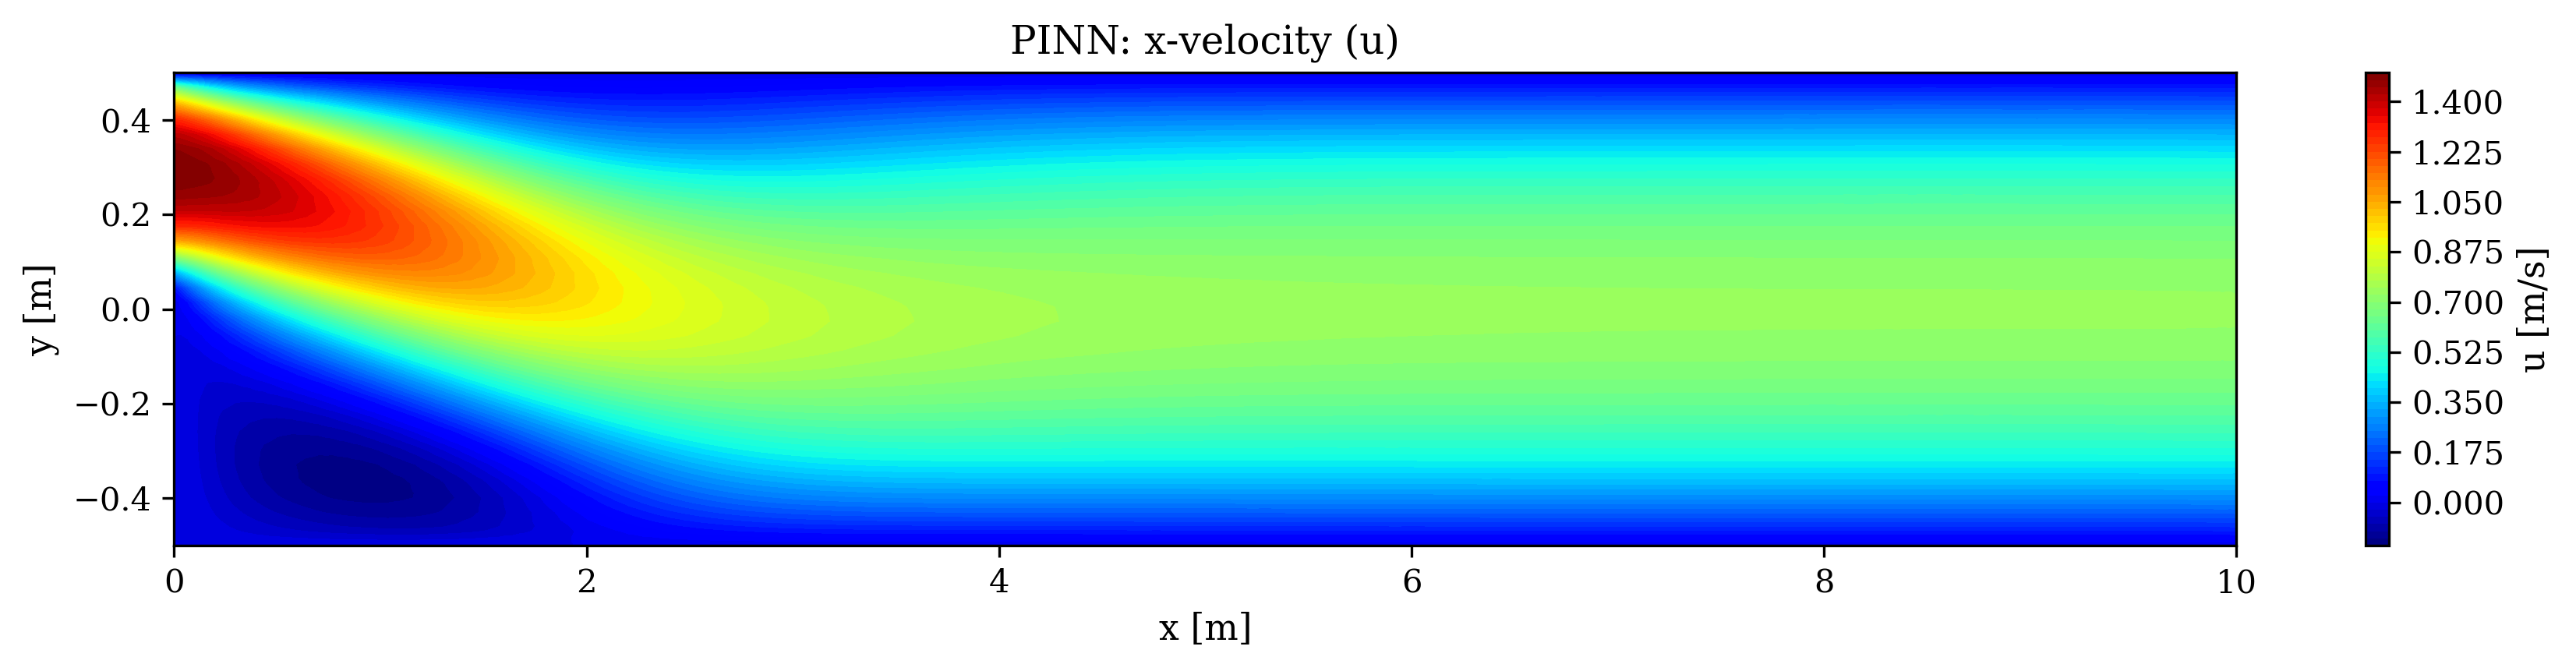

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/u_pinn.png


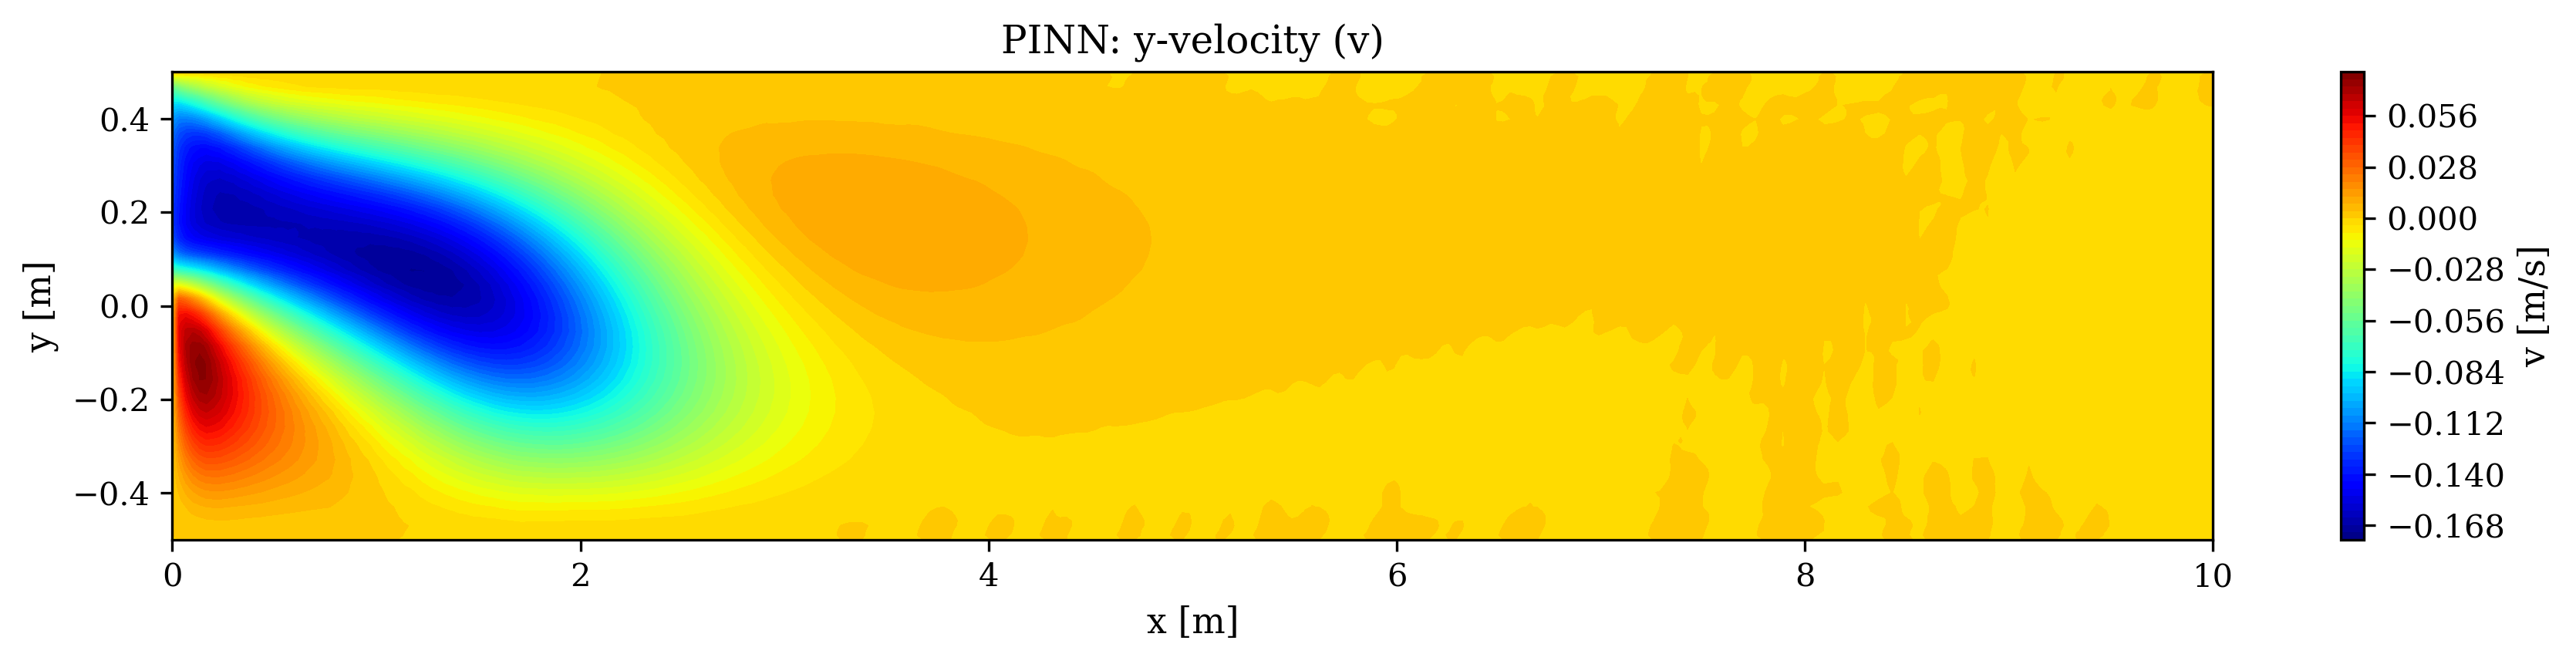

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/v_pinn.png


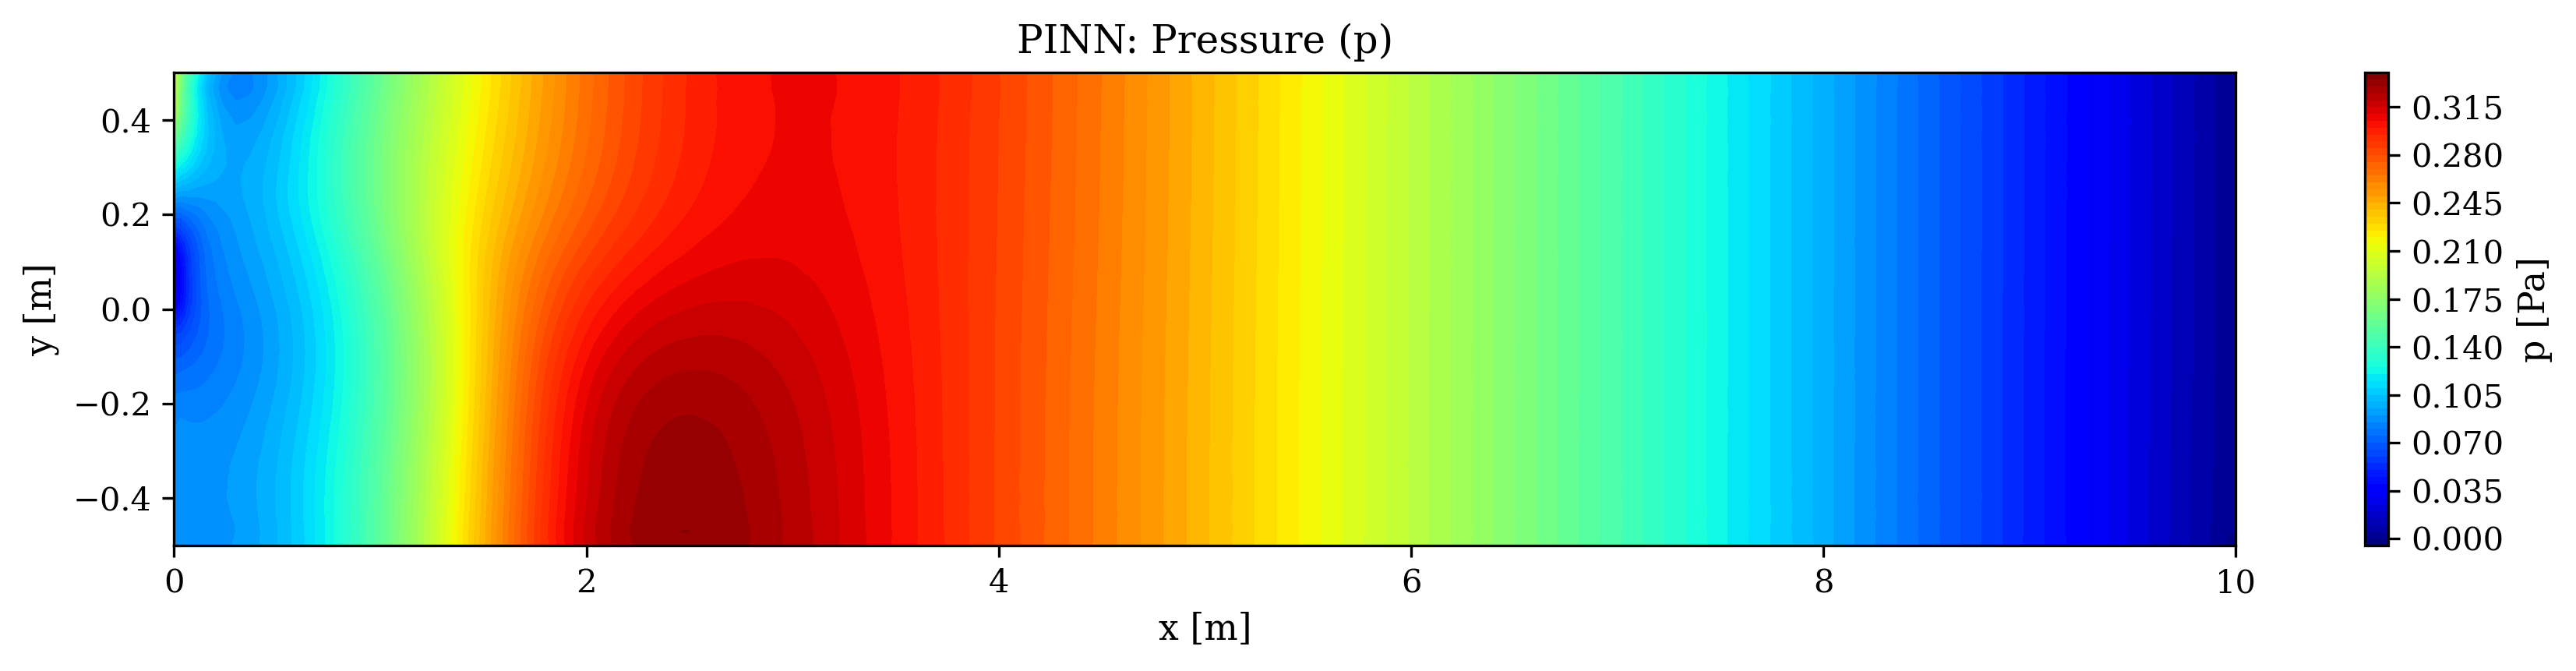

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/p_pinn.png


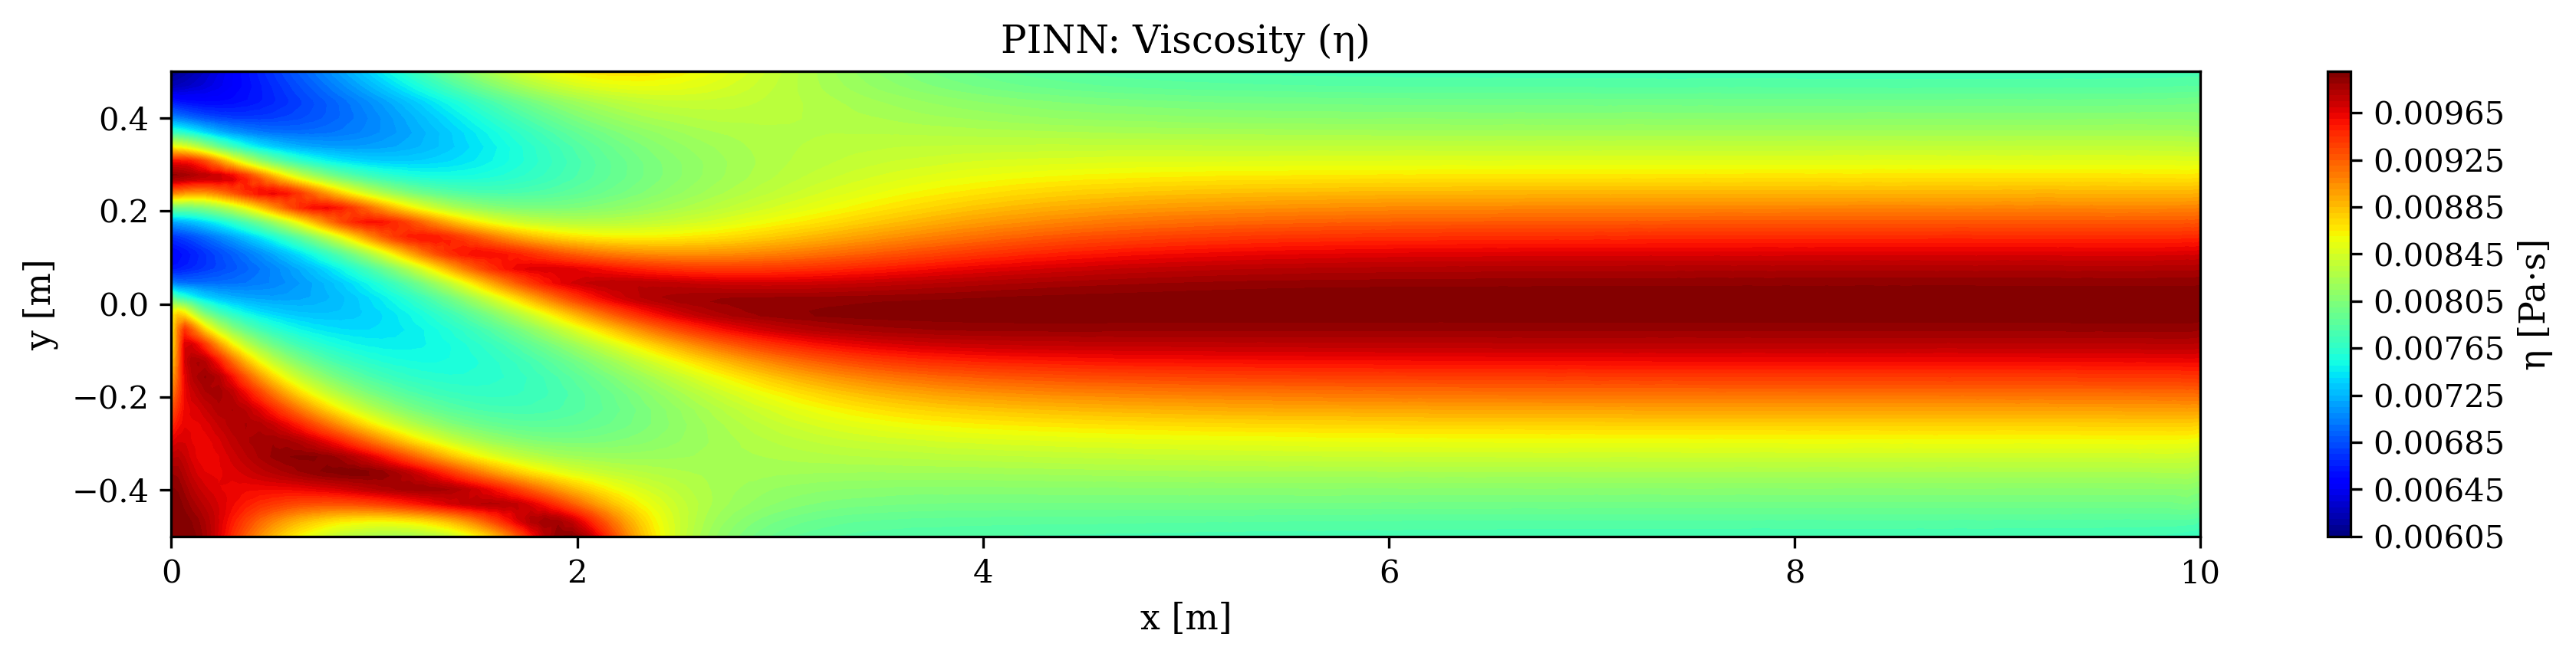

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/viscosity_pinn.png


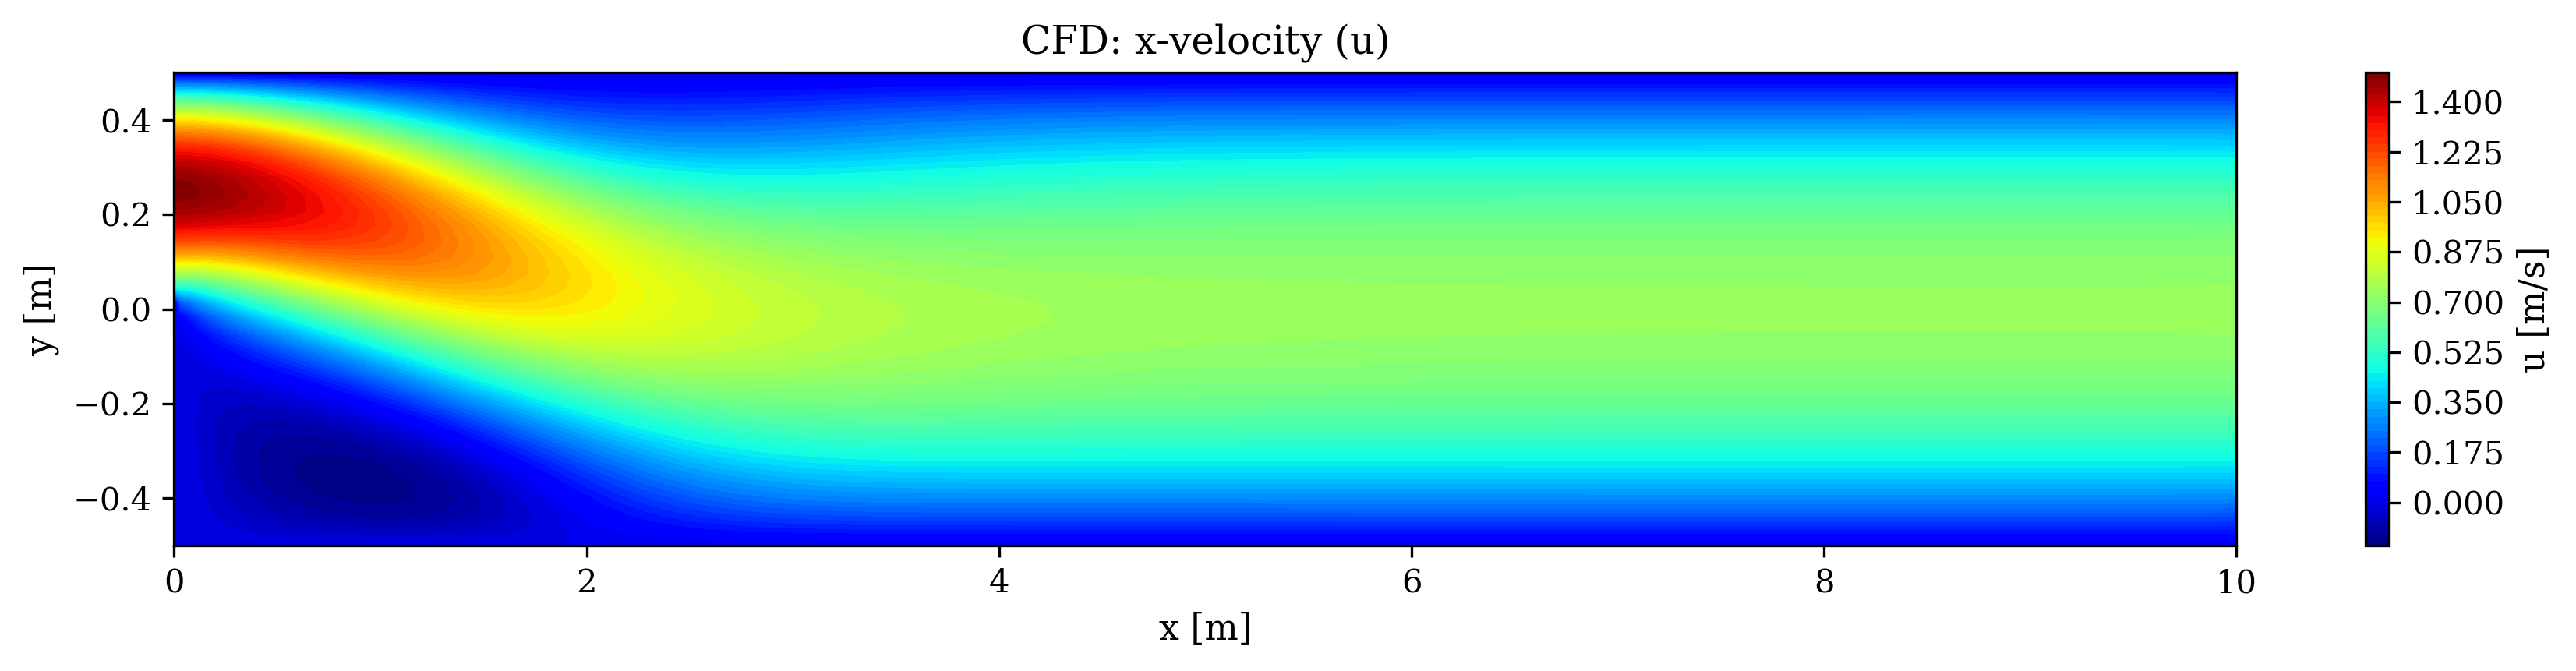

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/u_cfd.png


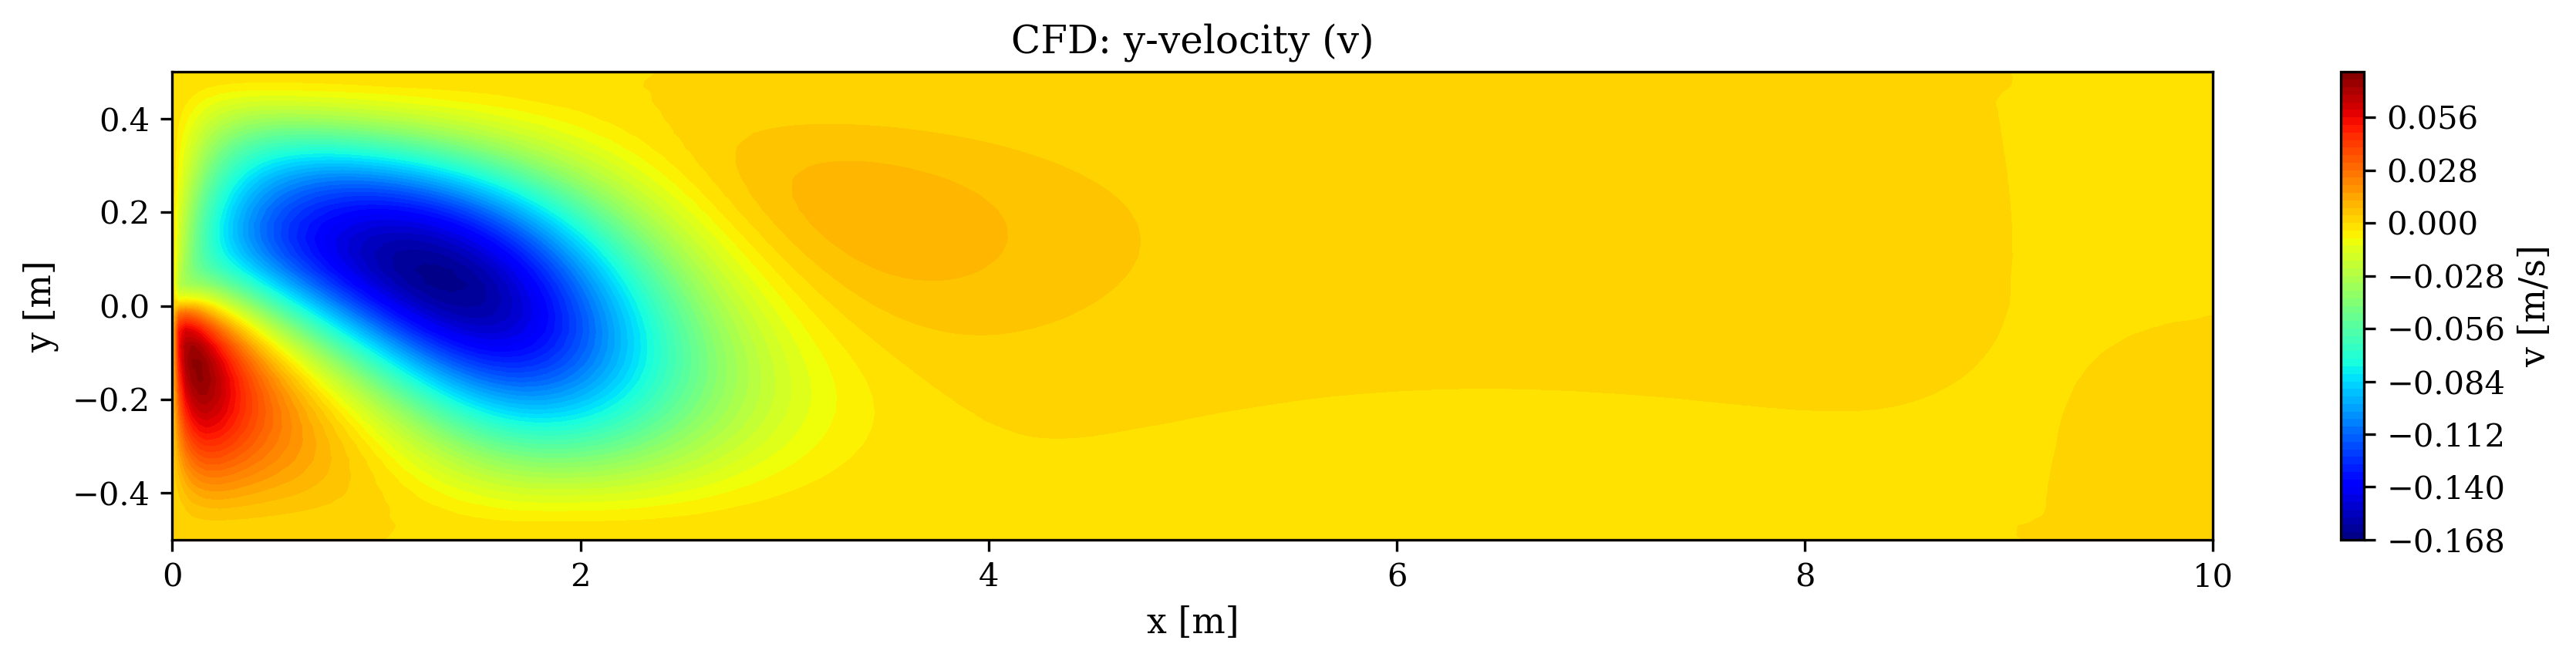

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/v_cfd.png


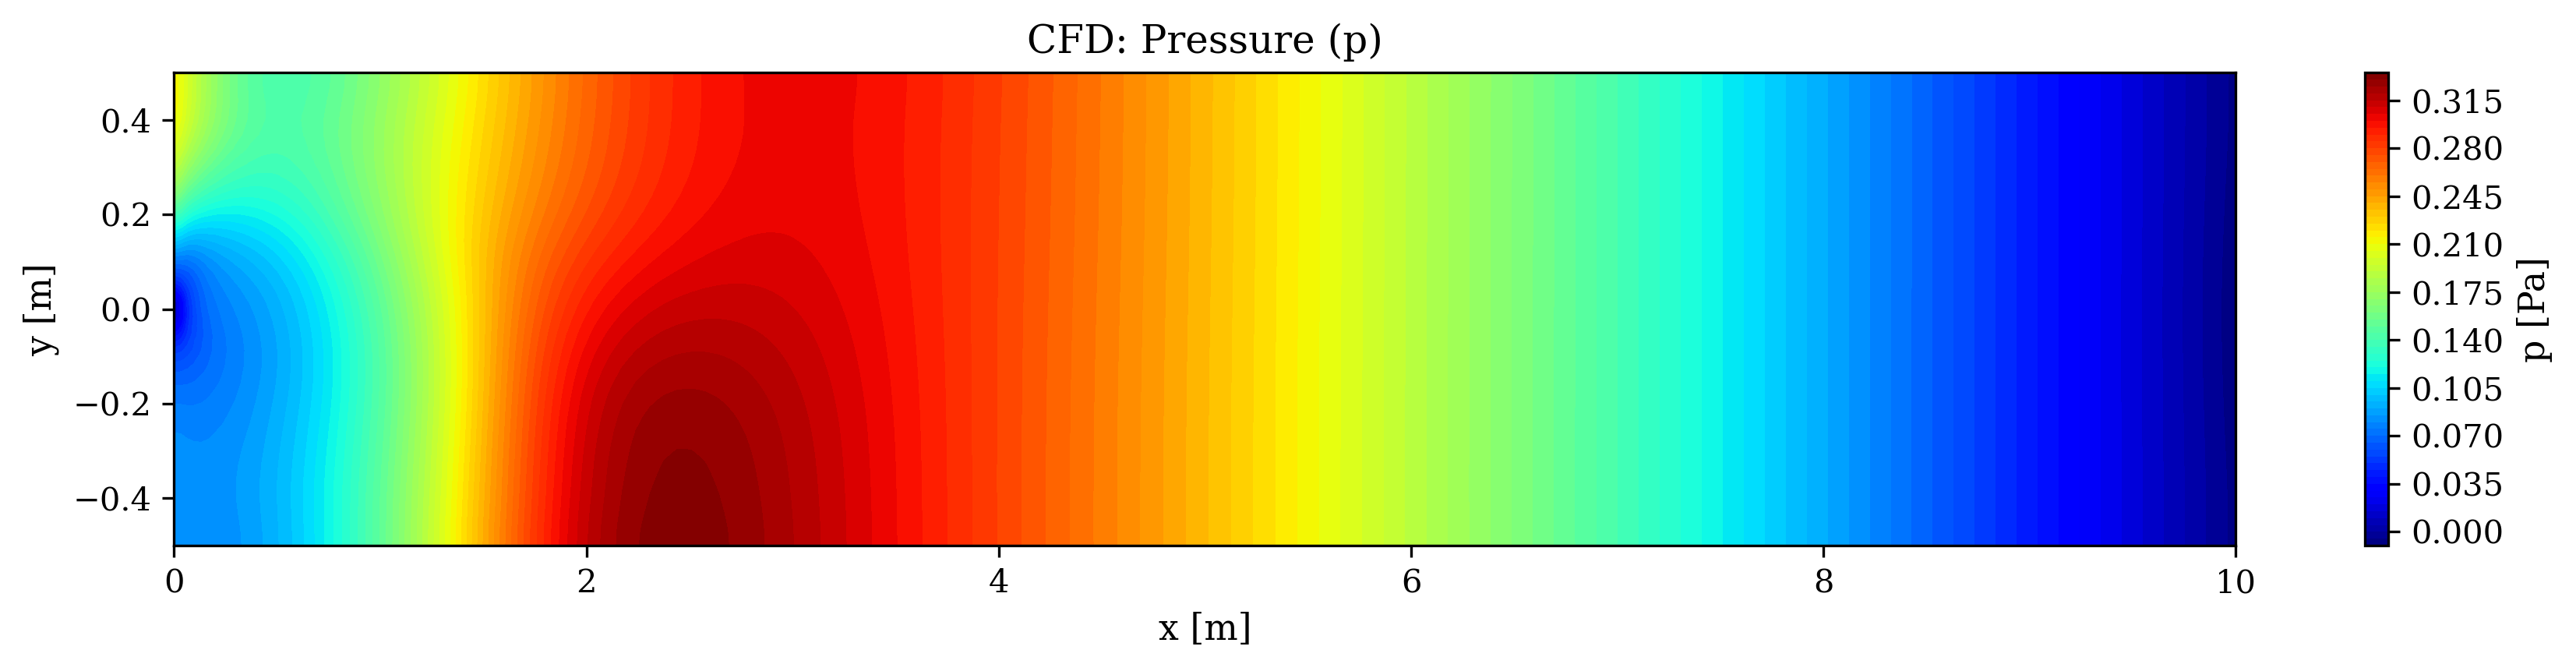

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/p_cfd.png


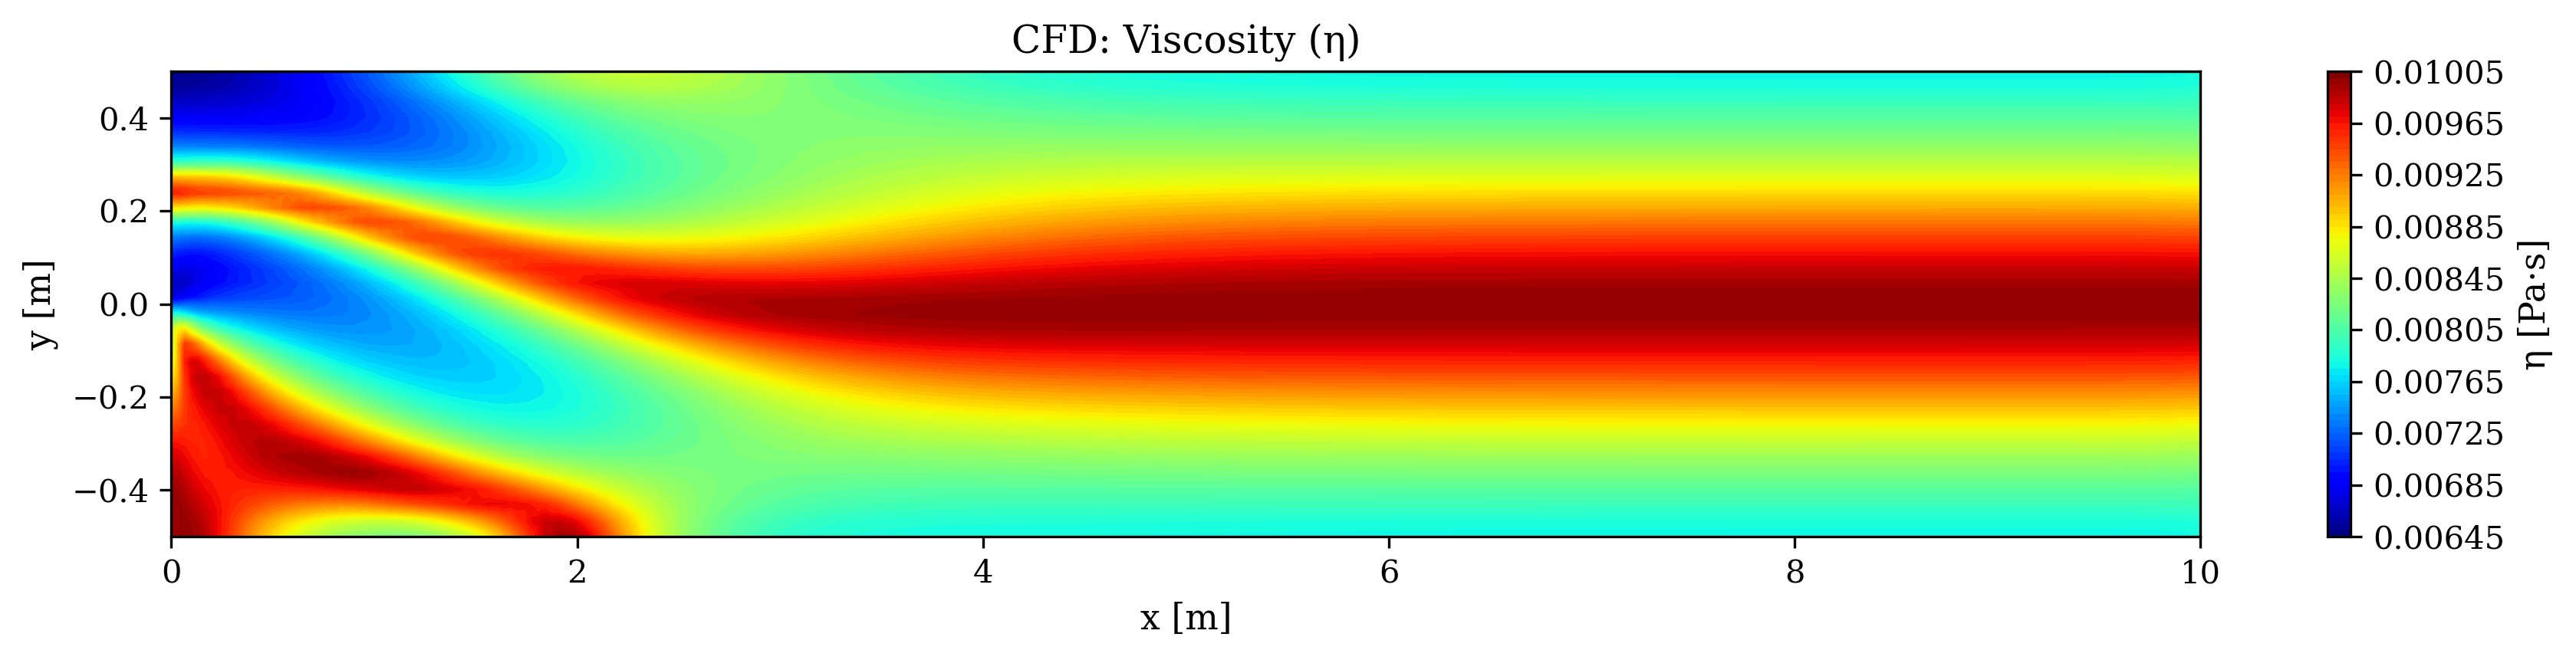

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/viscosity_cfd.png


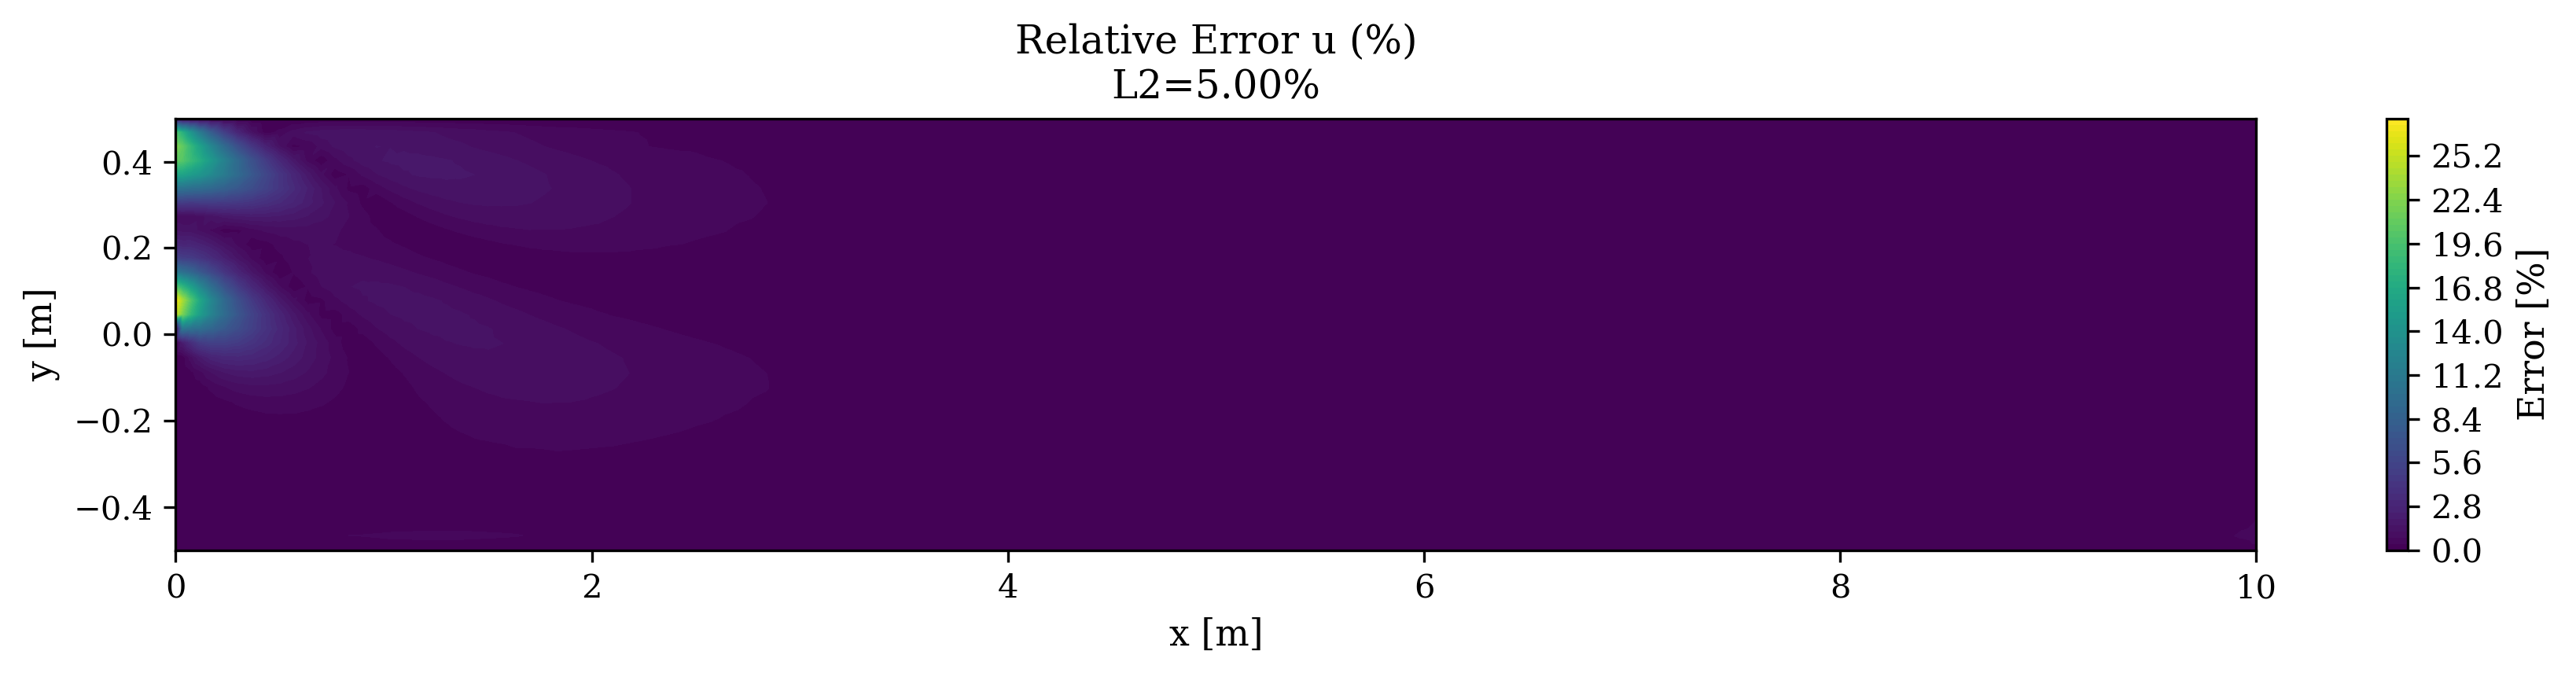

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/error_u_rel.png


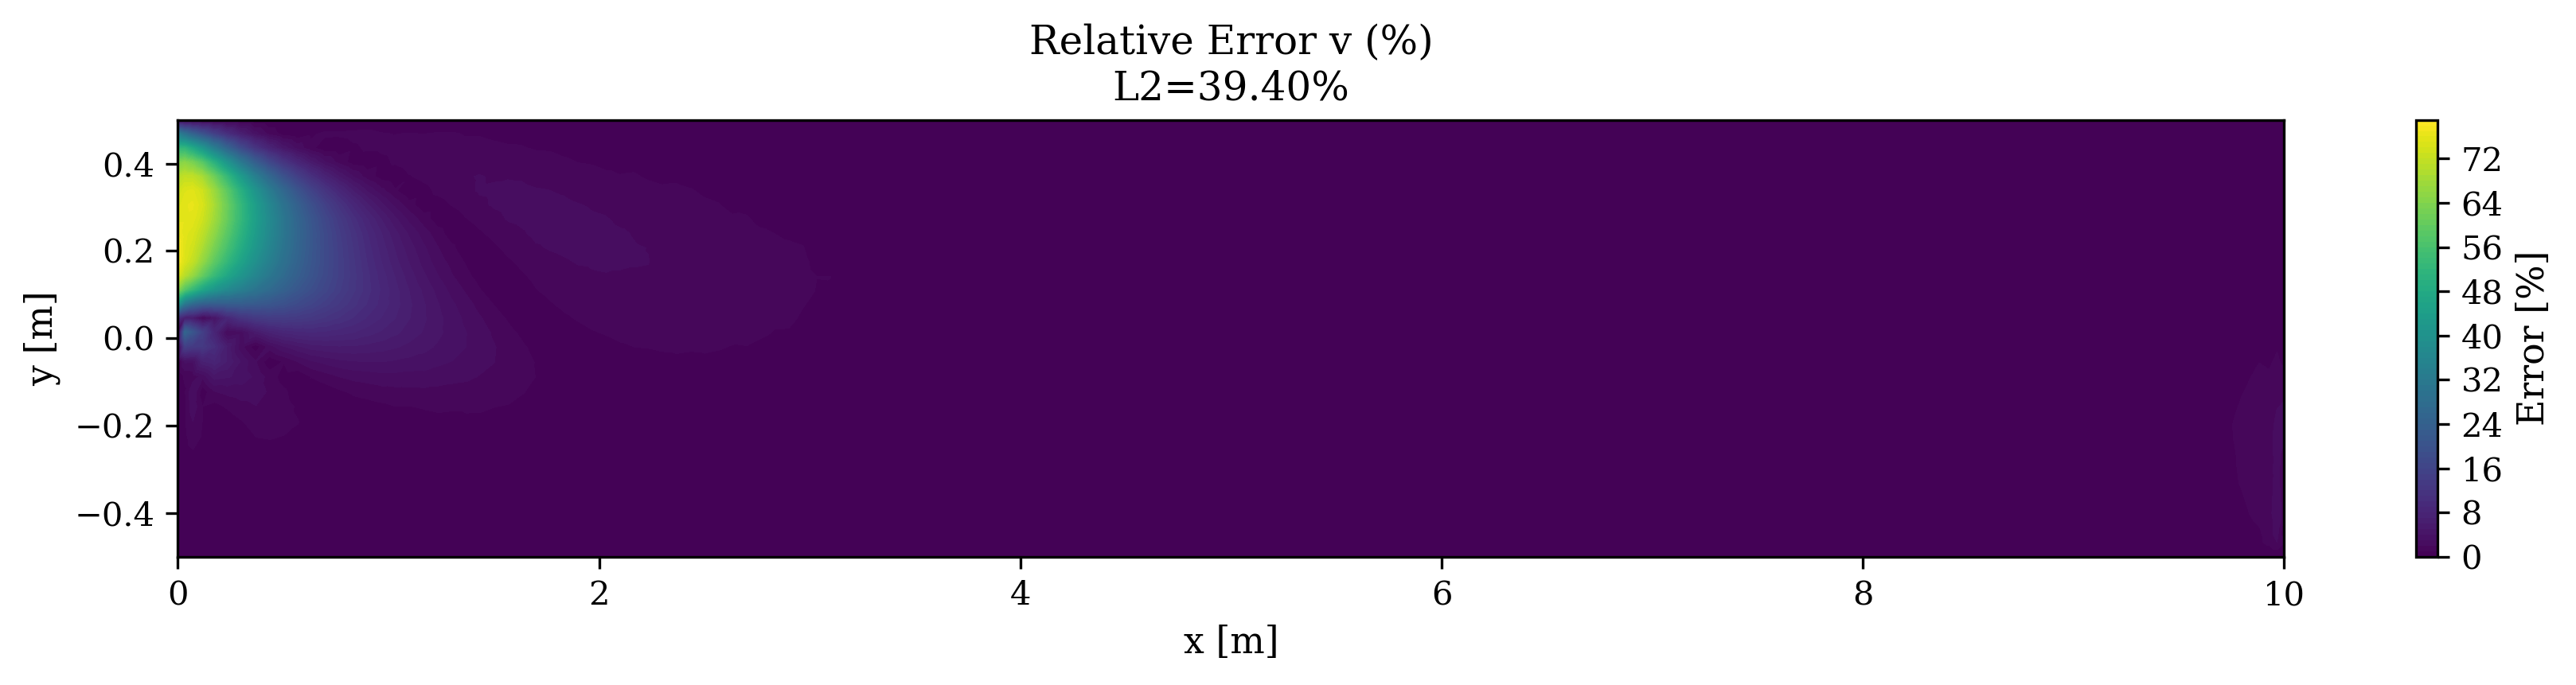

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/error_v_rel.png


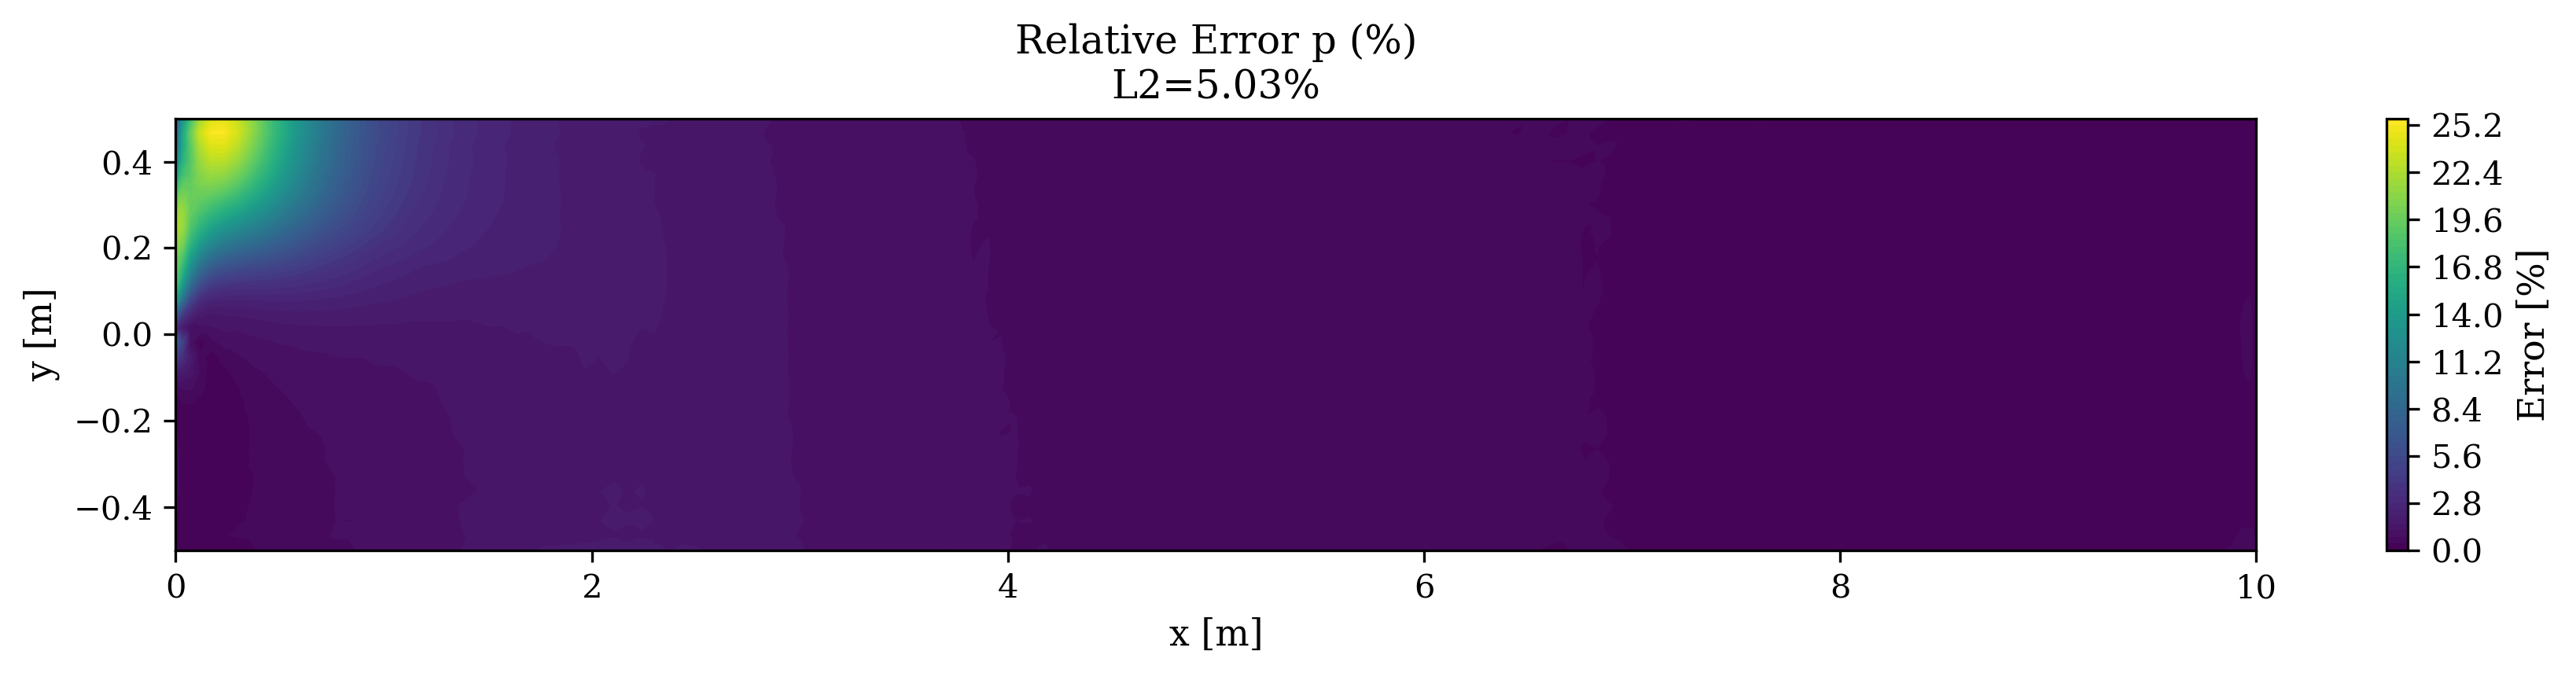

Saved -> GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/error_p_rel.png


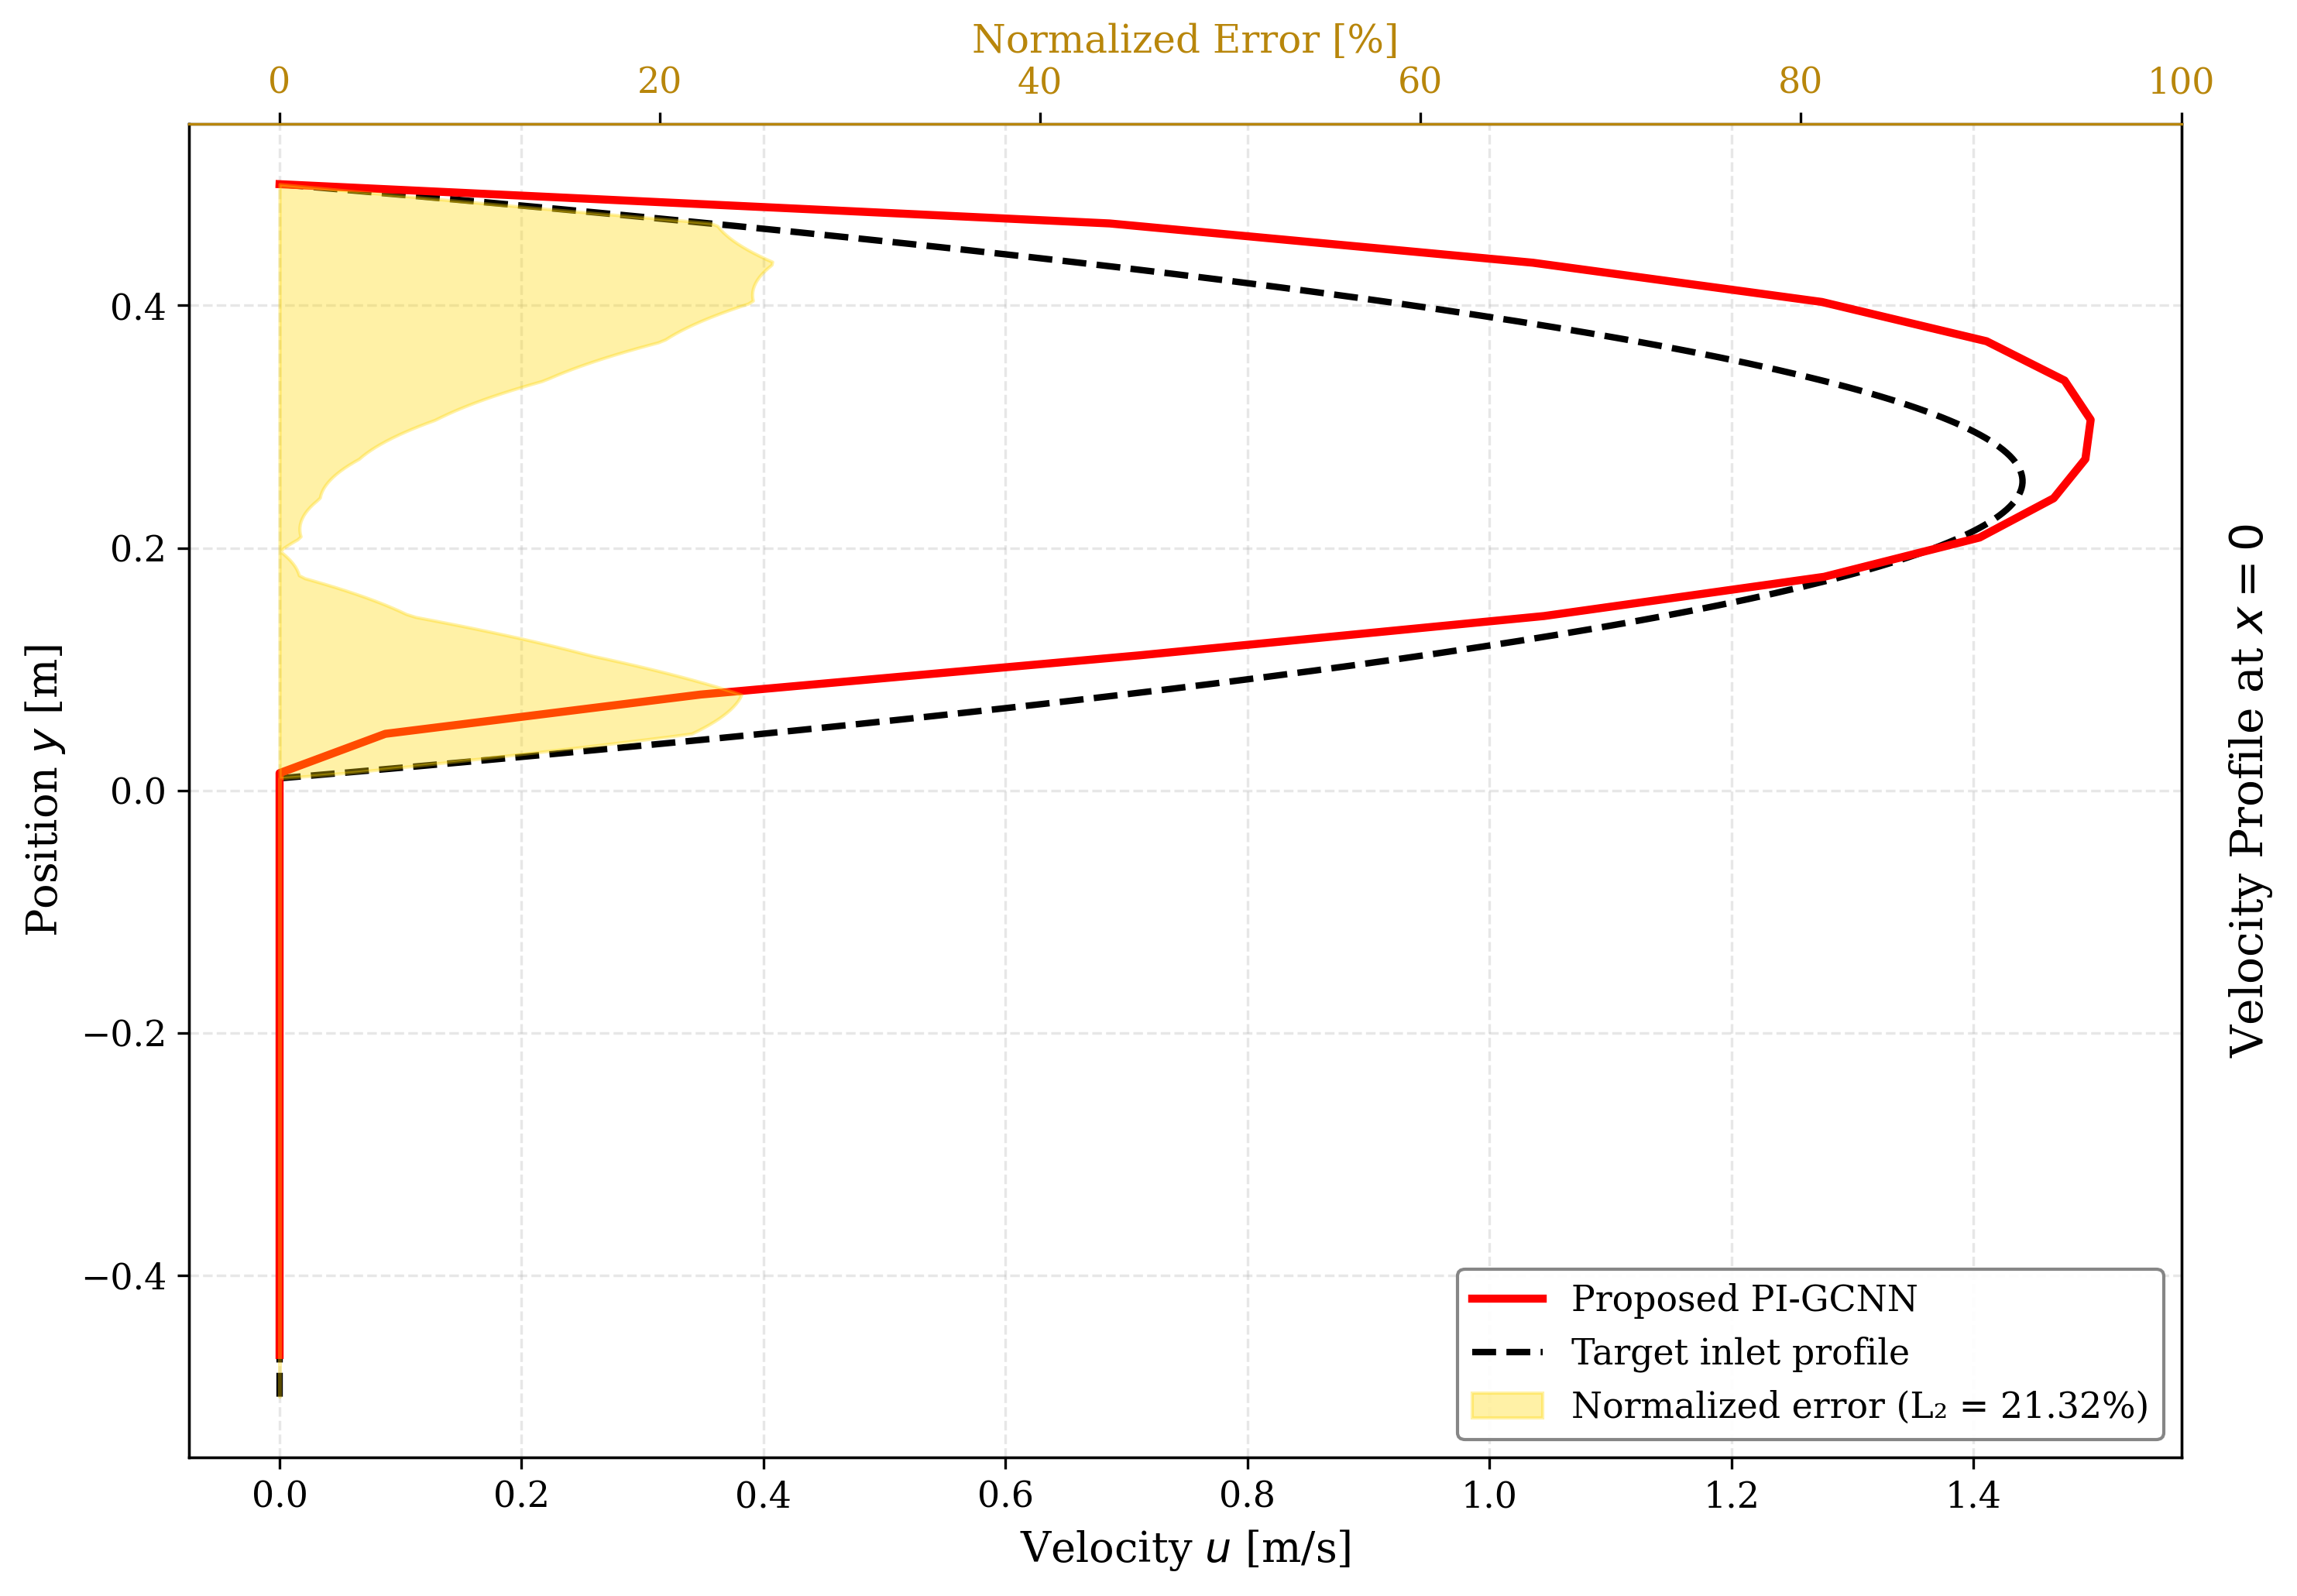

L₂ error = 21.32%
Saved → GPINN-illpose-100data-without-noise-tanhpattern-Results/plots/u_profile_x0.png


In [8]:
net = Pinns()
net.network.load_state_dict(torch.load(os.path.join(DIRS["models"], "model_best.pth")))
net.train(num_epochs=20000)
net.plot()

In [58]:
import shutil
import os
folder_path = 'GPINN-illpose-20data-10-noise-sinpattern-Results'
#shutil.rmtree(folder_path)